# Sea-level rise projections at the tide gauge

**Indicator:** projected **relative** sea-level change at the national tide gauge (cm, relative to the 1995–2014 mean), from the IPCC AR6 sea-level projections **including vertical land motion** (VLM), the projections used by the [NASA Pacific Flooding Analysis Tool](https://sealevel.nasa.gov/flooding-analysis-tool-pacific-islands/sea-level-rise).

AR6 provides projections at the PSMSL tide gauges. The UHSLC gauge selected in the [sea-level site setup](../../../historical/National/sea_level/00_sea_level_setup.ipynb) is matched to the nearest AR6 tide-gauge location. Projections are shown for the four SSP scenarios and reported at the **global warming levels** (+1.5, +2.0, +2.5 and +3.0 °C above 1850–1900) used by the other projection notebooks, together with the observed annual mean sea level at the gauge.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

warnings.filterwarnings('ignore', category=RuntimeWarning)

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level_station_projections.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level_station_projections.py).')
sys.path.insert(0, str(repo_root / 'functions'))

import projections as prj
from data_downloaders import download_uhslc_data
from sea_level import (build_output_filename, build_site_tag, load_site_config, save_dict_json, save_table_to_csv,
                       sea_level_config_path, station_series)
from sea_level_station_projections import (
    SSP_SCENARIOS, annual_projection, load_ar6_locations, match_stations, observed_annual_relative,
    plot_station_projection, scenario_color, scenario_label, warming_level_years,
)

## 1. Configuration

`site_key` selects the sea-level configuration of the historical analysis (`data/sites/sea_level/<site_key>.json`), which defines the UHSLC gauge. The year each SSP first reaches each warming level comes from [`../00_warming_levels.ipynb`](../00_warming_levels.ipynb). The AR6 files are downloaded on first use (only the required members of the Zenodo archive, ~75 MB per scenario, deleted once the tide-gauge and Pacific-grid values are cached in `data/projections/regional/`).

In [3]:
site_key = 'Palau'  # sea-level configuration written by historical/National/sea_level/00_sea_level_setup.ipynb
site_cfg = load_site_config(sea_level_config_path(repo_root, site_key))

country = site_cfg['country']
uhslc_id = int(site_cfg['selected_uhslc_id'])
station = site_cfg['station']
station_lon, station_lat = float(site_cfg['station_lon']), float(site_cfg['station_lat'])
sea_level_dir = repo_root / site_cfg['sea_level_data_dir']
site_name = site_cfg['site_name']
site_tag = build_site_tag(site_name, station_lon, station_lat)
fig_dir = repo_root / 'outputs' / 'figures' / site_tag
tab_dir = repo_root / 'outputs' / 'tables' / site_tag
for directory in (fig_dir, tab_dir):
    directory.mkdir(parents=True, exist_ok=True)

def out(name, ext='png'):
    return build_output_filename(f'PRJ_{name}', site_name, station_lon, station_lat, ext=ext)

# AR6 projections with vertical land motion (relative sea level, as recorded by the tide gauge)
ssp_scenarios = list(SSP_SCENARIOS)
raw_dir = repo_root / 'data' / 'projections' / 'sea_level'
locations_cache = repo_root / 'data' / 'projections' / 'regional' / 'sl_ar6_vlm_medium_locations.nc'
max_match_km = 30
force_download = False
print(f'{station}, {country} (UHSLC {uhslc_id:03d}); outputs in {fig_dir.relative_to(repo_root)}')

warming_levels = (1.5, 2.0, 2.5, 3.0)
gwl_years = warming_level_years(prj.load_warming_levels(ssp_scenarios))
pd.DataFrame(gwl_years).T.astype('Int64').astype(str).replace('<NA>', 'not reached').rename(columns=lambda c: f'+{c:g} °C').rename(index=scenario_label)

Malakal, Palau (UHSLC 007); outputs in outputs/figures/palau_uhslc007_lat7p329_lon134p450


,+1.5 °C,+2 °C,+2.5 °C,+3 °C
SSP1-2.6,2032,not reached,not reached,not reached
SSP2-4.5,2030,2052,2079,not reached
SSP3-7.0,2030,2046,2061,2075
SSP5-8.5,2027,2041,2053,2064


## 2. AR6 projection at the gauge

In [4]:
locs = load_ar6_locations(raw_dir, locations_cache, ssp_scenarios, force_download=force_download)
match = match_stations(locs, pd.DataFrame([{'uhslc_id': uhslc_id, 'name': station, 'lon': station_lon, 'lat': station_lat}]),
                       max_km=max_match_km).iloc[0]
change = locs['change'].sel(location=int(match['ar6_location']))   # cm, (scenario, quantile, year)
print(f"AR6 {match['ar6_kind']} {int(match['ar6_location'])} at {match['ar6_lon']:.2f}°E, {match['ar6_lat']:.2f}°N, "
      f"{match['ar6_distance_km']:.1f} km from the UHSLC gauge ({locs.attrs['product']}, VLM {locs.attrs['vertical_land_motion']}).")

annual = annual_projection(change).sel(year=slice(None, 2150))   # cm, annual, anchored at 0 in 2005

AR6 tide gauge 1252 at 134.47°E, 7.33°N, 2.2 km from the UHSLC gauge (regional total, medium confidence, VLM included).


## 3. Observed and projected sea level

The observed curve is the annual mean of the UHSLC daily record (years with at least 75 % of days), expressed relative to its own 1995–2014 mean so that it shares the AR6 baseline. Projections are AR6 decadal values interpolated to annual steps, anchored at zero in 2005 (centre of the baseline). Markers show the year each scenario reaches each global warming level.

Observed baseline: 1995–2014 mean (20 complete years); 55 complete years (1970–2025).


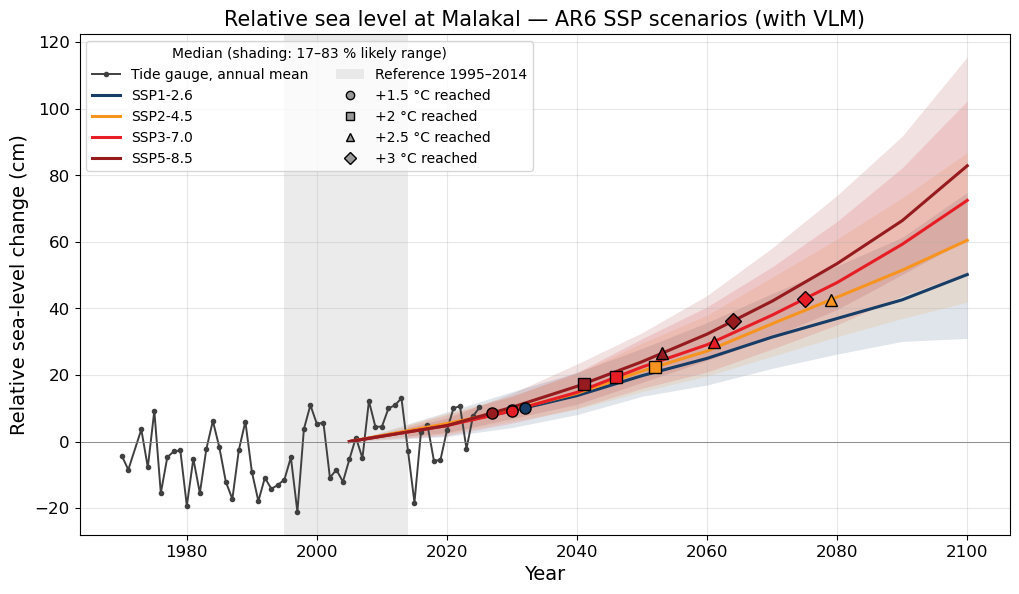

In [5]:
daily = station_series(download_uhslc_data(sea_level_dir, uhslc_id, 'daily'))
observed, baseline_note = observed_annual_relative(daily)
print(f'Observed baseline: {baseline_note}; {len(observed)} complete years ({observed.index.min()}–{observed.index.max()}).')

markers = {1.5: 'o', 2.0: 's', 2.5: '^', 3.0: 'D'}
fig, ax = plot_station_projection(change, observed, title=f'Relative sea level at {station} — AR6 SSP scenarios (with VLM)',
                                  end_year=2100)
for scenario, levels in gwl_years.items():
    for level, year in levels.items():
        ax.plot(year, float(annual.sel(scenario=scenario, quantile=0.5, year=year)), markers[level], ms=8,
                color=scenario_color(scenario), markeredgecolor='k', zorder=5)
for level, m in markers.items():
    ax.plot([], [], m, color='0.6', markeredgecolor='k', label=f'+{level:g} °C reached')
ax.legend(loc='upper left', fontsize=10, ncol=2, title='Median (shading: 17–83 % likely range)', title_fontsize=10)
fig.savefig(fig_dir / out('SL_station_projection_ssp'), dpi=200, bbox_inches='tight')
plt.show()

## 4. Projected change at the global warming levels

Median (likely range, 17th–83rd percentiles) relative sea-level change in cm relative to 1995–2014, in the year each SSP first reaches each warming level.

In [6]:
rows = []
for scenario, levels in gwl_years.items():
    for level, year in levels.items():
        c = annual.sel(scenario=scenario, year=year)
        rows.append({'scenario': scenario, 'level': level, 'year': year,
                     **{f'change_q{q:g}_cm': round(float(c.sel(quantile=q)), 1) for q in (0.05, 0.17, 0.5, 0.83, 0.95)}})
gwl_table = pd.DataFrame(rows)
summary = gwl_table.assign(
    Scenario=gwl_table['scenario'].map(scenario_label),
    level_label=gwl_table['level'].map(lambda v: f'+{v:g} °C'),
    value=gwl_table.apply(lambda r: f"{r['change_q0.5_cm']:.0f} ({r['change_q0.17_cm']:.0f}–{r['change_q0.83_cm']:.0f}) in {int(r['year'])}", axis=1),
).pivot(index='Scenario', columns='level_label', values='value').reindex(
    index=[scenario_label(s) for s in ssp_scenarios], columns=[f'+{v:g} °C' for v in warming_levels]).fillna('not reached')
save_table_to_csv(gwl_table, tab_dir, out('SL_station_projection_warming_levels', 'csv'))
save_table_to_csv(summary.reset_index(), tab_dir, out('SL_station_projection_summary', 'csv'))
summary

level_label,+1.5 °C,+2 °C,+2.5 °C,+3 °C
Scenario,,,,
SSP1-2.6,10 (5–16) in 2032,not reached,not reached,not reached
SSP2-4.5,10 (6–14) in 2030,22 (16–31) in 2052,43 (31–60) in 2079,not reached
SSP3-7.0,9 (6–14) in 2030,19 (14–27) in 2046,30 (22–42) in 2061,43 (31–59) in 2075
SSP5-8.5,9 (6–12) in 2027,17 (12–24) in 2041,26 (20–36) in 2053,36 (27–50) in 2064


### Contribution of vertical land motion

Difference between the projections with and without VLM at the same AR6 tide-gauge location (`ar6-regional_novlm-confidence`, cached by the [regional notebook](../../Regional/sea_level/regional_indicators.ipynb)), in the year each SSP reaches each warming level. Positive values mean subsidence adds to relative sea-level rise; negative values mean uplift reduces it.

In [7]:
novlm_cache = repo_root / 'data' / 'projections' / 'regional' / 'sl_ar6_novlm_medium_pacific.nc'
vlm_rows = None
if novlm_cache.is_file() and match['ar6_kind'] == 'tide gauge':
    novlm = xr.load_dataset(novlm_cache)
    loc_id = int(match['ar6_location'])
    if loc_id in novlm.gauge.values:
        novlm_annual = annual_projection(novlm['gauge_change'].sel(gauge=loc_id, scenario=ssp_scenarios, quantile=0.5))
        rows = []
        for scenario, levels in gwl_years.items():
            for level, year in levels.items():
                w = float(annual.sel(scenario=scenario, quantile=0.5, year=year))
                wo = float(novlm_annual.sel(scenario=scenario, year=year))
                rows.append({'Scenario': scenario_label(scenario), 'Warming level': f'+{level:g} °C', 'Year': year,
                             'with VLM (cm)': round(w, 1), 'without VLM (cm)': round(wo, 1),
                             'VLM contribution (cm)': round(w - wo, 1)})
        vlm_rows = pd.DataFrame(rows)
        save_table_to_csv(vlm_rows, tab_dir, out('SL_station_vlm_contribution', 'csv'))
if vlm_rows is None:
    print('No no-VLM projection available for this location: run the regional projection notebook first.')
vlm_rows

,Scenario,Warming level,Year,with VLM (cm),without VLM (cm),VLM contribution (cm)
0,SSP1-2.6,+1.5 °C,2032,10.1,10.1,-0.0
1,SSP2-4.5,+1.5 °C,2030,9.5,9.5,0.0
2,SSP2-4.5,+2 °C,2052,22.4,22.3,0.1
3,SSP2-4.5,+2.5 °C,2079,42.6,42.4,0.2
4,SSP3-7.0,+1.5 °C,2030,9.2,9.2,-0.0
5,SSP3-7.0,+2 °C,2046,19.4,19.2,0.2
6,SSP3-7.0,+2.5 °C,2061,30.0,29.8,0.2
7,SSP3-7.0,+3 °C,2075,42.9,42.7,0.2
8,SSP5-8.5,+1.5 °C,2027,8.7,8.6,0.1
9,SSP5-8.5,+2 °C,2041,17.3,17.2,0.2


## 5. Saved outputs

In [8]:
long_table = annual.sel(year=slice(2020, 2150)).to_dataframe().reset_index()[['scenario', 'quantile', 'year', 'change']]
long_table['scenario'] = long_table['scenario'].map(scenario_label)
save_table_to_csv(long_table.round(2), tab_dir, out('SL_station_projection_annual', 'csv'))

metrics = {
    'station': station, 'uhslc_id': uhslc_id,
    'ar6_location': int(match['ar6_location']), 'ar6_kind': match['ar6_kind'], 'ar6_distance_km': float(match['ar6_distance_km']),
    'vertical_land_motion': locs.attrs['vertical_land_motion'], 'reference_period': '1995–2014',
    'observed_baseline': baseline_note,
}
for _, r in gwl_table.iterrows():
    metrics[f"{r['scenario']}_gwl{r['level']:g}_{int(r['year'])}_cm"] = [r['change_q0.17_cm'], r['change_q0.5_cm'], r['change_q0.83_cm']]
save_dict_json(metrics, tab_dir, out('SL_station_projection_metrics', 'json'))
pd.Series(metrics).to_frame('value')

,value
station,Malakal
uhslc_id,7
ar6_location,1252
ar6_kind,tide gauge
ar6_distance_km,2.2
vertical_land_motion,included
reference_period,1995–2014
observed_baseline,1995–2014 mean (20 complete years)
ssp126_gwl1.5_2032_cm,"[5.0, 10.1, 16.2]"
ssp245_gwl1.5_2030_cm,"[6.0, 9.5, 13.7]"


## Interpretation and reproducibility notes

- **Source:** IPCC AR6 WGI sea-level projections (Fox-Kemper et al., 2021; Garner et al., 2021, Zenodo [10.5281/zenodo.6382554](https://doi.org/10.5281/zenodo.6382554)), `ar6-regional-confidence`, total, medium confidence.
- **Relative sea level:** these projections include vertical land motion estimated by AR6 from tide-gauge, GNSS and glacial-isostatic information, so they describe what the tide gauge should record. They differ from the absolute (no-VLM) maps of the regional notebook.
- **Matching:** the UHSLC gauge is matched to the nearest AR6 (PSMSL) tide-gauge location within 30 km; when there is none, the nearest ocean grid cell is used, whose VLM term is less specific to the gauge.
- **Warming levels:** values are read in the year each SSP first reaches the level (IPCC AR6 multi-model mean global surface temperature), as in the other CIndRA projection notebooks. Sea level responds slowly, so the same warming level reached later (lower scenarios) comes with more sea-level rise; a level not reached by 2100 is reported as *not reached*.
- **Uncertainty:** shading and ranges are the AR6 likely range (17–83 %). Medium confidence excludes low-likelihood, high-impact ice-sheet processes.